# ACCESS-OM3 and ACCESS-OM2 timeseries
Includes both scalar variables and spatial averages of 2d variables.

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
# esm_file = "/g/data/ol01/outputs/access-om3-25km/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"
#esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# ACCESS-OM2 reference: an ACCESS-NRI intake catalog key, e.g. "025deg_jra55_iaf_omip2_cycle6";
# None = chosen from the forcing mode, nominal resolution and IAF cycle of esm_file (ignored for ACCESS-CM3)
om2_reference_override = None

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/"
nbname = "timeseries.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from exptdata_access import guess_experiment_from_esm_file, get_exptname_from_path
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]  # OM3 or CM3

In [4]:
%matplotlib inline
from model_agnostic import patch_broken_conda_env, patch_dask_workers
patch_broken_conda_env()  # conda env workaround; no-op on healthy envs

import pandas as pd
import intake
import xarray as xr
import numpy as np
import cf_xarray as cfxr
import pint_xarray
from pint import application_registry as ureg
import cf_xarray.units
import cftime
import xgcm
import os
import re

import matplotlib.pyplot as plt
import cmocean as cm
import cartopy.crs as ccrs
import cartopy.feature as cft

from dask.distributed import Client

In [5]:
xr.set_options(keep_attrs=True); # cf_xarray works best when xarray keeps attributes by default

In [6]:
client = Client(threads_per_worker=1)
patch_dask_workers(client)  # patch workers too
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 188.56 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:36389,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:45695,Total threads: 1
Dashboard: http://127.0.0.1:34961/status,Memory: 11.78 GiB
Nanny: tcp://127.0.0.1:42797,


In [7]:
thisdir = './'

In [8]:
# Identify the forcing mode, nominal resolution and IAF cycle of the experiment under test.
# The forcing mode decides which experiments are compared; all three decide the ACCESS-OM2 reference.

def name_tokens(text):
    """
    Split an experiment name or path into lower-case tokens.
    """
    return set(re.split(r"[_+\-./]", text.lower()))

def forcing_mode(text):
    """
    Return 'iaf' or 'ryf' if exactly one of them is a token of text, else None.
    """
    modes = name_tokens(text) & {"iaf", "ryf"}
    return modes.pop() if len(modes) == 1 else None

def nominal_resolution(text):
    """
    Return '100km', '25km' or '8km' if exactly one of them is a token of text, else None.
    """
    resolutions = name_tokens(text) & {"100km", "25km", "8km"}
    return resolutions.pop() if len(resolutions) == 1 else None

def iaf_cycle(text):
    """
    Return the IAF cycle number from a 'cycleN' tag in text, defaulting to 1.
    """
    match = re.search(r"cycle(\d+)", text.lower())
    return int(match.group(1)) if match else 1

exptname = get_exptname_from_path(esm_file)

if model_name == "ACCESS-CM3":
    # Coupled model: there is no prescribed forcing mode or OM3 nominal resolution
    forcing, resolution, cycle = None, None, None
else:
    # Prefer the experiment name; fall back to the full path (e.g. .../access-om3-25km/...)
    forcing = forcing_mode(exptname) or forcing_mode(esm_file)
    resolution = nominal_resolution(exptname) or nominal_resolution(esm_file)
    if forcing is None or resolution is None:
        raise ValueError(f"Cannot identify forcing mode (iaf/ryf) and nominal resolution "
                         f"(100km/25km/8km) of {exptname} from {esm_file}")
    cycle = iaf_cycle(exptname) if forcing == "iaf" else None

IAF = forcing == "iaf"

print("Experiment under test:", exptname)
print("Forcing mode:", forcing)
print("Nominal resolution:", resolution)
print("IAF cycle:", cycle)

Experiment under test: MC_25km_jra_iaf+wombatlite-test5.1-8f50b769
Forcing mode: iaf
Nominal resolution: 25km
IAF cycle: 1


### Define data sources

In [9]:
# Candidate experiments to compare with the experiment under test.
# Only candidates with the same model and forcing mode (IAF/RYF) are used, so this list can hold any mix
# of experiments. Nominal resolution may differ: IAF runs share calendar years, so e.g. 25km and 100km IAF
# runs are directly comparable (resolution still selects the ACCESS-OM2 reference below).
candidate_catalogs = [
                # '/g/data/ol01/access-om3-output/access-om3-025/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json',
                '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-COARE-12fab415/datastore.json',
                '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json',
                '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/datastore.json',
                "/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_iaf+wombatlite-test1-e1de2a94/experiment_datastore.json",  # 100km IAF, JRA55-do forcing
                "/g/data/ol01/outputs/access-om3-100km/MC_100km_era_iaf-test1-1d86aa55/experiment_datastore.json",    # 100km IAF, ERA5 forcing
                "/g/data/ol01/outputs/access-om3-100km/MCW_100km_era_iaf-test1-961264ad/experiment_datastore.json",   # 100km IAF, ERA5 forcing, with waves
                "/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c/experiment_datastore.json",   # 100km RYF spin-up
            ]

def comparable(path):
    """True if the experiment at path has the same model and forcing mode as the experiment under test."""
    name = get_exptname_from_path(path)
    if guess_experiment_from_esm_file(path)[1]["model"] != model_name:
        return False
    if model_name == "ACCESS-CM3":
        return True
    return (forcing_mode(name) or forcing_mode(path)) == forcing

catalogs = [esm_file]  # the CM3/OM3 experiment under test
for path in dict.fromkeys(candidate_catalogs):  # drop duplicates, keep order
    if get_exptname_from_path(path) == exptname:
        continue
    if comparable(path):
        catalogs.append(path)
    else:
        print("Skipping (different model or forcing mode):", get_exptname_from_path(path))

print("Experiments compared:")
for path in catalogs:
    print(" -", get_exptname_from_path(path))

Skipping (different model or forcing mode): MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c
Experiments compared:
 - MC_25km_jra_iaf+wombatlite-test5.1-8f50b769
 - MC_25km_jra_iaf+wombatlite-test3v2-00532b88
 - MC_25km_jra_iaf+wombatlite-test4-d28e0359
 - MC_100km_jra_iaf+wombatlite-test1-e1de2a94
 - MC_100km_era_iaf-test1-1d86aa55
 - MCW_100km_era_iaf-test1-961264ad


In [10]:
datastores = { get_exptname_from_path(c):
               intake.open_esm_datastore(c, columns_with_iterables=['variable'])
              for c in catalogs }
datastores

{'MC_25km_jra_iaf+wombatlite-test5.1-8f50b769': <datastore catalog with 24 dataset(s) from 11154 asset(s)>,
 'MC_25km_jra_iaf+wombatlite-test3v2-00532b88': <datastore catalog with 24 dataset(s) from 32927 asset(s)>,
 'MC_25km_jra_iaf+wombatlite-test4-d28e0359': <datastore catalog with 24 dataset(s) from 32795 asset(s)>,
 'MC_100km_jra_iaf+wombatlite-test1-e1de2a94': <experiment_datastore catalog with 24 dataset(s) from 11154 asset(s)>,
 'MC_100km_era_iaf-test1-1d86aa55': <experiment_datastore catalog with 19 dataset(s) from 6164 asset(s)>,
 'MCW_100km_era_iaf-test1-961264ad': <experiment_datastore catalog with 20 dataset(s) from 30770 asset(s)>}

In [11]:
if model_name == "ACCESS-CM3":
    # ACCESS-CM2 cj877 control run reference (as in other CM3 notebooks).
    # Its scalar diagnostics use the same variable names as the OM2 catalog.
    om2expt = 'cj877'
    import glob
    _cm2_files = sorted(glob.glob('/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn/ocean-scalar-1-daily-ym_*.nc'))
    om2cat = xr.open_mfdataset(_cm2_files, combine="by_coords", parallel=True, chunks={"time": 181},
                               decode_timedelta=False, use_cftime=True,
                               data_vars="minimal", coords="minimal", compat="override")
else:
    # ACCESS-OM2 reference with the same nominal resolution and forcing mode as the experiment under test.
    # IAF: the OM2 IAF cycle matching the OM3 cycle (cycle 1 unless the experiment name says otherwise),
    #      so both runs are at the same stage of spin-up.
    # RYF: the RYF9091 control runs - see https://forum.access-hive.org.au/t/access-om2-control-experiments/258
    # All OM2 references are JRA55-do forced, including for ERA5-forced OM3 experiments.
    def om2_reference(resolution, forcing, cycle=1):
        if forcing == "ryf":
            return {
                "100km": "1deg_jra55_ryf9091_gadi",
                "25km": "025deg_jra55_ryf9091_gadi",
                "8km": "01deg_jra55v13_ryf9091",
            }[resolution]
        if resolution == "8km":  # 0.1deg cycle 1 has no "_cycle1" suffix
            return "01deg_jra55v140_iaf" if cycle == 1 else f"01deg_jra55v140_iaf_cycle{cycle}"
        prefix = {"100km": "1deg", "25km": "025deg"}[resolution]
        return f"{prefix}_jra55_iaf_omip2_cycle{cycle}"

    om2expt = om2_reference_override or om2_reference(resolution, forcing, cycle)
    if om2expt not in intake.cat.access_nri:
        raise ValueError(f"ACCESS-OM2 reference {om2expt} is not in the ACCESS-NRI intake catalog; "
                         f"set om2_reference_override")
    om2cat = intake.cat.access_nri[om2expt]

print("Reference experiment:", om2expt)

Reference experiment: 025deg_jra55_iaf_omip2_cycle1


### Load grid data
This is needed for xgcm so we can get spatial averages of non-scalar data.

In [12]:
exptname = get_exptname_from_path(esm_file)
# filename regex matches om3 and cm3 static files
static = xr.open_dataset(datastores[exptname].search(filename=".*mom6.static.nc").df.loc[0, "path"]).drop_vars("time")

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x15171431be60>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1517140c5730>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1517140c7bc0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1517140b8260>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1517142c35f0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1517140cb650>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x151712a2af00>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [13]:
# See https://xgcm.readthedocs.io/en/latest/xgcm-examples/03_MOM6/#xgcm-grid-definition
symmetric = True  # True for ACCESS-OM3 2025.08.000 and later

if symmetric:  # ACCESS-OM3 version 2025.08.000 and later: one more q point than h points
    coords={
        'X': {'center': 'xh', 'outer': 'xq'},
        'Y': {'center': 'yh', 'outer': 'yq'},
        # 'Z': { 'inner': 'zl', 'outer': 'zi'}
    }
else:  # ACCESS-OM3 versions prior to 2025.08.000: equal number of q and h points
    coords={
        'X': {'center': 'xh', 'right': 'xq'},
        'Y': {'center': 'yh', 'right': 'yq'},
        # 'Z': { 'inner': 'zl', 'outer': 'zi'}
    }

grid = xgcm.Grid(
    static,
    coords=coords,
    metrics = {
        ('X',): ['dxt', 'dxCu', 'dxCv'], # X distances
        ('Y',): ['dyt', 'dyCu', 'dyCv'], # Y distances
        ('X', 'Y'): ['areacello', 'areacello_cu', 'areacello_cv', 'areacello_bu'] # Areas
    },
    periodic=['X'],
    autoparse_metadata=False
# Note, autoparse_metadata=False is required below for xgcm >= 0.9.0 to prevent xgcm 
# from trying to autoparse non-existent grid information from the file metadata, 
# leading to the error:
# ValueError: Found two coordinates without `c_grid_axis_shift` attribute for axis X
)

### Define list of variables and load them

In [14]:
fields = { # key is OM3 name, value is OM2 name
    # 'mlotst': 'mld',
    # keys from ncdump -h ctrl_run_25km_0.5/archive/output009/access-om3.mom6.scalar.1day.snap.1962.nc | grep double
    'masso': None, # Mass of liquid ocean
    'soga': 'salt_global_ave',
    'thetaoga': 'temp_global_ave', # BUG: is OM2 potential temperature? https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/3#issuecomment-3736872326
    'tosga': 'temp_surface_ave',   # BUG: is OM2 potential temperature? https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/3#issuecomment-3736872326
    'sosga': 'salt_surface_ave',
    'speed_max': None,
    'mlotst_max': None,
    'tos_max': None,
    'tos_min': None,
    'sos_max': None,
    'sos_min': None,
    'zos_max': None,
    'zos_min': None, 
    'total_salt_Flux_Added': None,
    'total_salt_Flux_In': None,
    'total_salt_flux': None,
    'net_fresh_water_global_adjustment': None,
    'salt_flux_global_restoring_adjustment': None,
    'salt_flux_global_restoring_scaling': None,  # used instead of the adjustment when ADJUST_NET_SRESTORE_BY_SCALING = True
    'total_wfo': None,
    'total_evs': None,
    'total_fsitherm': None,
    'total_precip': None,
    'total_prsn': None,
    'total_lprec': None,
    'total_ficeberg': None,
    'total_friver': None,
    'total_net_massout': None,
    'total_net_massin': None,
}
fields

{'masso': None,
 'soga': 'salt_global_ave',
 'thetaoga': 'temp_global_ave',
 'tosga': 'temp_surface_ave',
 'sosga': 'salt_surface_ave',
 'speed_max': None,
 'mlotst_max': None,
 'tos_max': None,
 'tos_min': None,
 'sos_max': None,
 'sos_min': None,
 'zos_max': None,
 'zos_min': None,
 'total_salt_Flux_Added': None,
 'total_salt_Flux_In': None,
 'total_salt_flux': None,
 'net_fresh_water_global_adjustment': None,
 'salt_flux_global_restoring_adjustment': None,
 'salt_flux_global_restoring_scaling': None,
 'total_wfo': None,
 'total_evs': None,
 'total_fsitherm': None,
 'total_precip': None,
 'total_prsn': None,
 'total_lprec': None,
 'total_ficeberg': None,
 'total_friver': None,
 'total_net_massout': None,
 'total_net_massin': None}

In [15]:
# from https://github.com/COSIMA/cosima-recipes/blob/main/Cooking-Lessons-101-Tutorials/ACCESS-NRI_Intake_Catalog.ipynb
# Speeding up opening your datasets
# Try passing the following argument to your to_dask or to_dataset_dict call:
# See the xarray documentation on Reading multi-file datasets for more details about these arguments.
# https://docs.xarray.dev/en/stable/user-guide/io.html#reading-multi-file-datasets

xarray_combine_by_coords_kwargs=dict(
    compat="override",
    data_vars="minimal",
    coords="minimal"
)

In [16]:
# Load data one experiment at a time, so a field that is missing from, or ambiguous in,
# one experiment does not affect the others.

# Searches tried in turn when a variable has more than one frequency or cell method in a datastore
fallback_searches = [
    {},
    {"frequency": "1mon", "variable_cell_methods": ".*time: mean.*"},
    {"variable_cell_methods": ".*time: mean.*"},
    {"variable_cell_methods": ".*time: point.*"},
    {"variable_cell_methods": ".*time: min.*"},
    {"variable_cell_methods": ".*time: max.*"},
]

def load_variable(datastore, variable, frequency=None, **to_dask_kwargs):
    """
    Open `variable` from an intake-esm datastore, or return None if the datastore doesn't have it.
    If `frequency` is given, that output frequency is tried first, so that comparison experiments and
    the reference use the same frequency as the experiment under test where they can.
    """
    if datastore.search(variable=variable).df.empty:
        return None
    searches = fallback_searches
    if frequency is not None:
        preferred = [{**s, "frequency": frequency} for s in fallback_searches]
        searches = []
        for s in preferred + fallback_searches:
            if s not in searches:
                searches.append(s)
    errors = []
    for search in searches:
        try:
            subset = datastore.search(variable=variable, **search)
        except NotImplementedError:  # e.g. regex on an iterable column, as in the ACCESS-NRI catalog
            continue
        if subset.df.empty:
            continue
        try:
            return subset.to_dask(**to_dask_kwargs)
        except ValueError as e:  # e.g. the search matches more than one dataset
            errors.append(f"{search}: {e}")
    print(f"  could not load {variable}; every search failed:")
    for e in errors:
        print("    " + e.splitlines()[0])
    return None

data = dict()
for k, om2 in fields.items():
    print(k)
    primary = load_variable(datastores[exptname], k,
                            xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs)
    if primary is None:
        print(f"  not output by {exptname}; skipped")
        continue
    if set(primary[k].dims) <= {"time", "scalar_axis"} and not bool((primary[k] != 0).any()):
        # e.g. salt_flux_global_restoring_adjustment when ADJUST_NET_SRESTORE_BY_SCALING = True
        print(f"  zero throughout in {exptname} (option not active); skipped")
        continue
    frequency = primary.attrs.get("intake_esm_attrs:frequency")

    d = {exptname: primary}
    for n, datastore in datastores.items():
        if n == exptname:
            continue
        ds = load_variable(datastore, k, frequency,
                           xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs)
        if ds is None:
            print(f"  not available from {n}")
        else:
            d[n] = ds

    # add reference model data, with variable name changed to match om3
    if om2 is None:
        d2 = {}
    elif model_name == "ACCESS-CM3":
        cm2_da = om2cat[[om2]].isel(scalar_axis=0, drop=True).rename({om2: k})  # drop dummy scalar_axis dim
        # relabel cj877 (cftime, model years) onto CM3's own datetime64 time axis,
        # matching elapsed time since each run's start (both are daily)
        _cm3t = d[exptname].time
        n = min(cm2_da.sizes["time"], _cm3t.sizes["time"])
        cm2_da = cm2_da.isel(time=slice(None, n)).assign_coords(time=("time", _cm3t.isel(time=slice(None, n)).values))
        d2 = {om2expt: cm2_da}
    else:
        # file-native chunks: auto-chunking fails on object-dtype variables (e.g. average_DT in OM2 RYF)
        reference = load_variable(om2cat, om2, frequency, xarray_open_kwargs={"chunks": {}})
        if reference is None:
            print(f"  {om2} not available from {om2expt}")
            d2 = {}
        else:
            d2 = {om2expt: reference.rename({om2: k})}

    data[k] = d2 | d

if IAF:
    for vname, d in data.items():
        for expt in d.keys():
            try:
                d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
            except KeyError:
                pass

data

masso


soga


thetaoga


tosga


sosga


speed_max


... (18 outputs left out)

total_friver


total_net_massout


total_net_massin


{'masso': {'MC_25km_jra_iaf+wombatlite-test5.1-8f50b769': <xarray.Dataset> Size: 386kB
  Dimensions:      (time: 24106, scalar_axis: 1)
  Coordinates:
    * time         (time) object 193kB 1958-01-02 00:00:00 ... 2024-01-01 00:00:00
    * scalar_axis  (scalar_axis) float64 8B 0.0
  Data variables:
      masso        (time, scalar_axis) float64 193kB dask.array<chunksize=(365, 1), meta=np.ndarray>
  Attributes: (12/15)
      title:                                    ACCESS-OM3
      grid_type:                                regular
      grid_tile:                                N/A
      intake_esm_vars:                          ['masso']
      intake_esm_attrs:file_id:                 ocean.1day.scalar_axis:1
      intake_esm_attrs:frequency:               1day
      ...                                       ...
      intake_esm_attrs:variable_cell_methods:   ['time: point', 'time: point', ...
      intake_esm_attrs:variable_units:          ['Celsius', 'kg', 'kg m-2 s-1',...
      in

In [17]:
data.keys()

dict_keys(['masso', 'soga', 'thetaoga', 'tosga', 'sosga', 'speed_max', 'mlotst_max', 'tos_max', 'tos_min', 'sos_max', 'sos_min', 'zos_max', 'zos_min', 'total_salt_Flux_Added', 'total_salt_Flux_In', 'total_salt_flux', 'total_wfo', 'total_evs', 'total_fsitherm', 'total_precip', 'total_prsn', 'total_lprec', 'total_ficeberg', 'total_friver', 'total_net_massout', 'total_net_massin'])

In [18]:
data

{'masso': {'MC_25km_jra_iaf+wombatlite-test5.1-8f50b769': <xarray.Dataset> Size: 386kB
  Dimensions:      (time: 24106, scalar_axis: 1)
  Coordinates:
    * time         (time) object 193kB 1958-01-02 00:00:00 ... 2024-01-01 00:00:00
    * scalar_axis  (scalar_axis) float64 8B 0.0
  Data variables:
      masso        (time, scalar_axis) float64 193kB dask.array<chunksize=(365, 1), meta=np.ndarray>
  Attributes: (12/15)
      title:                                    ACCESS-OM3
      grid_type:                                regular
      grid_tile:                                N/A
      intake_esm_vars:                          ['masso']
      intake_esm_attrs:file_id:                 ocean.1day.scalar_axis:1
      intake_esm_attrs:frequency:               1day
      ...                                       ...
      intake_esm_attrs:variable_cell_methods:   ['time: point', 'time: point', ...
      intake_esm_attrs:variable_units:          ['Celsius', 'kg', 'kg m-2 s-1',...
      in

### Plot timeseries

In [19]:
# set date range
# trange = slice(cftime.DatetimeNoLeap(1900, 1, 1, 0, 0, 0, 0),
#                cftime.DatetimeNoLeap(1960, 1, 1, 0, 0, 0, 0))
trange = slice(None, None)  # all available

# One fixed colour per experiment, the same in every panel and on every experiment's page: it comes from the
# experiment's position in candidate_catalogs (whether or not it is compared here), not from which experiment
# is under test. An experiment under test that is not a candidate is C0; the reference is black.
candidate_names = list(dict.fromkeys(get_exptname_from_path(p) for p in candidate_catalogs))
experiment_colours = {n: f"C{i % 9 + 1}" for i, n in enumerate(candidate_names)}
experiment_colours.setdefault(exptname, "C0")
experiment_colours[om2expt] = "k"

# Line style of the annual means shows the nominal resolution; the reference is solid
resolution_linestyles = {"100km": "-", "25km": "--", "8km": ":"}
experiment_linestyles = {
    get_exptname_from_path(p): resolution_linestyles.get(
        nominal_resolution(get_exptname_from_path(p)) or nominal_resolution(p), "-")
    for p in catalogs
}
experiment_linestyles[om2expt] = "-"

def plot_span(d, k):
    """
    Time span plotted for field k: that of the experiment under test, within trange.
    Comparison and reference runs are cut to it, so a longer run (e.g. a 780-year OM2 RYF control)
    sets neither the x nor the y axis range.
    """
    t = d[exptname][k].sel(time=trange).time
    return slice(t.values[0], t.values[-1])

masso


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries.md


Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries.md successfully.
soga


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries_02.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries.md
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries.md successfully.
thetaoga


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries_03.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries.md
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries.md successfully.
tosga


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries_04.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries.md
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries.md successfully.
sosga


... (19 outputs left out)

Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries_23.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries.md
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries.md successfully.
total_friver


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries_24.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries.md
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries.md successfully.
total_net_massout


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries_25.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries.md
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries.md successfully.
total_net_massin


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries_26.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries.md
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ba9f6aa/notebooks/mkfigs_output_MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/mkmd/timeseries.md successfully.


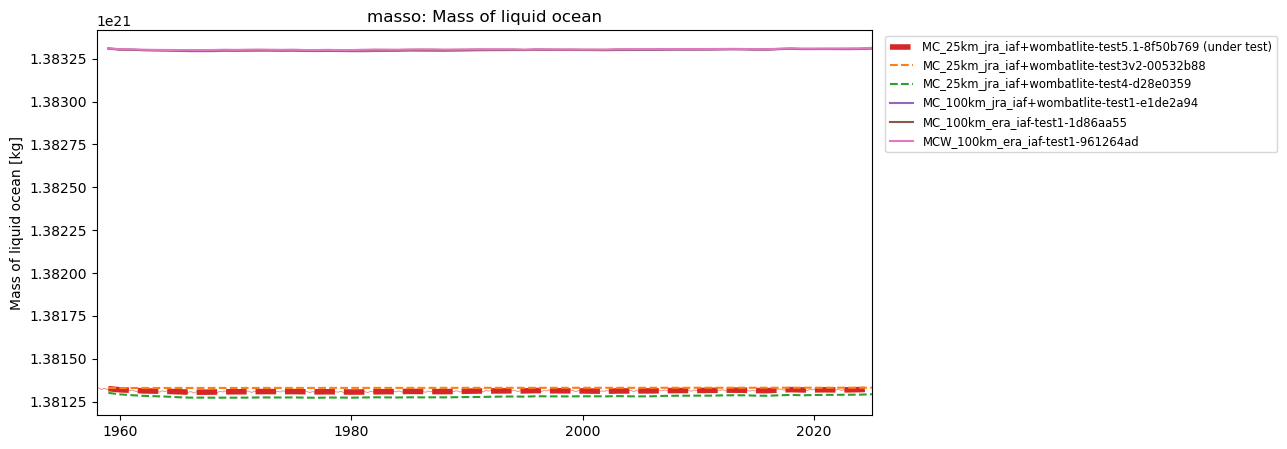

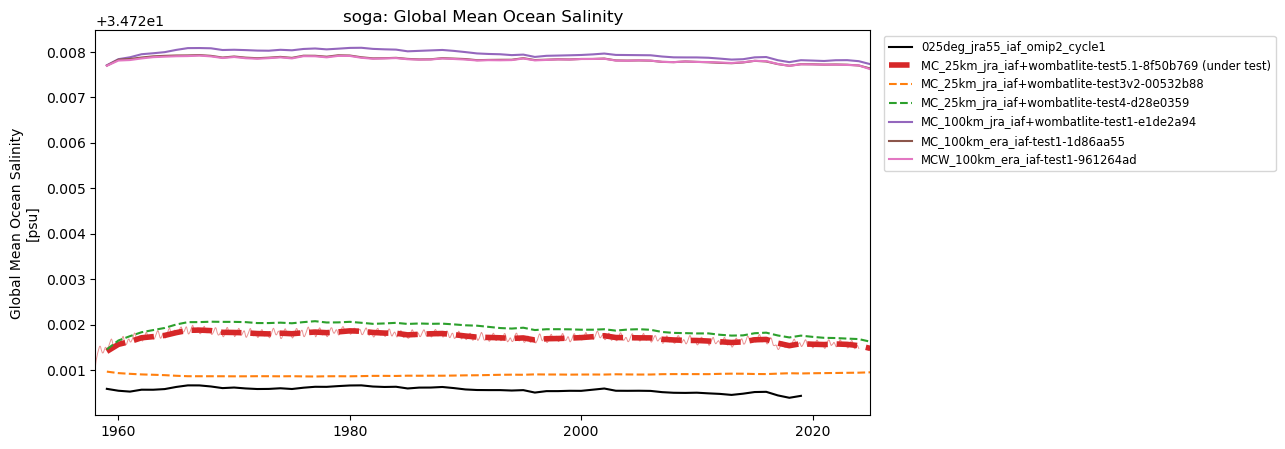

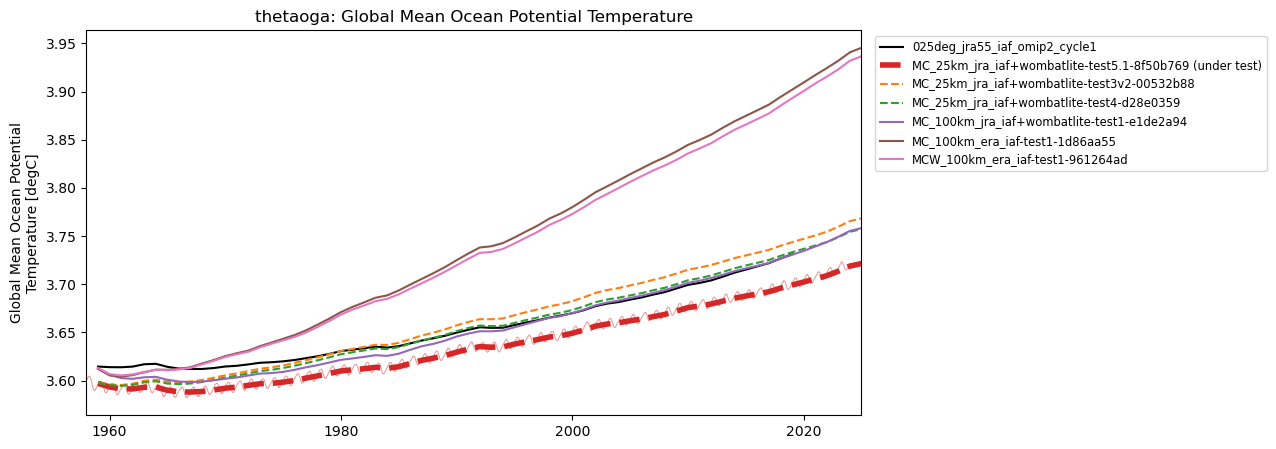

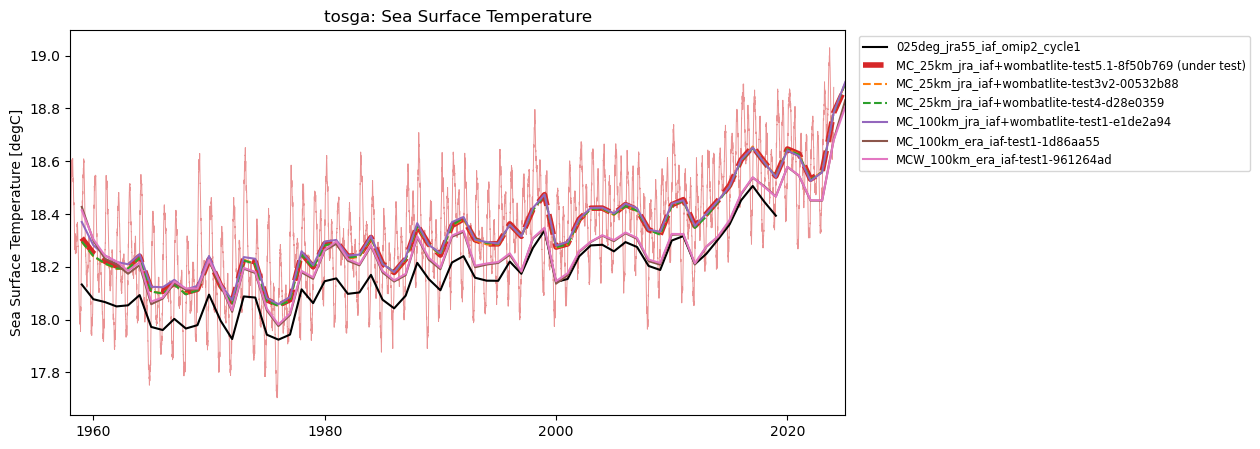

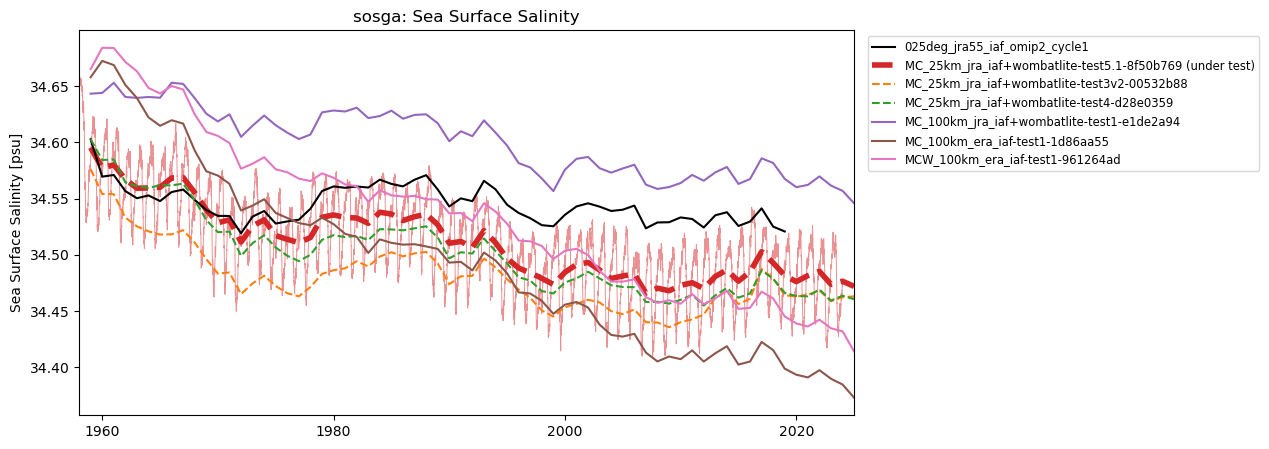

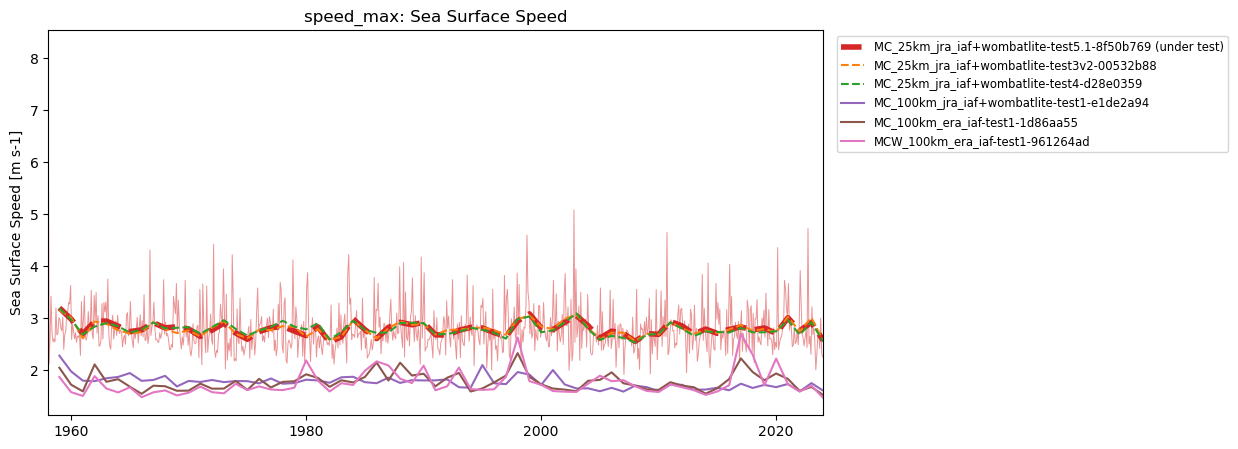

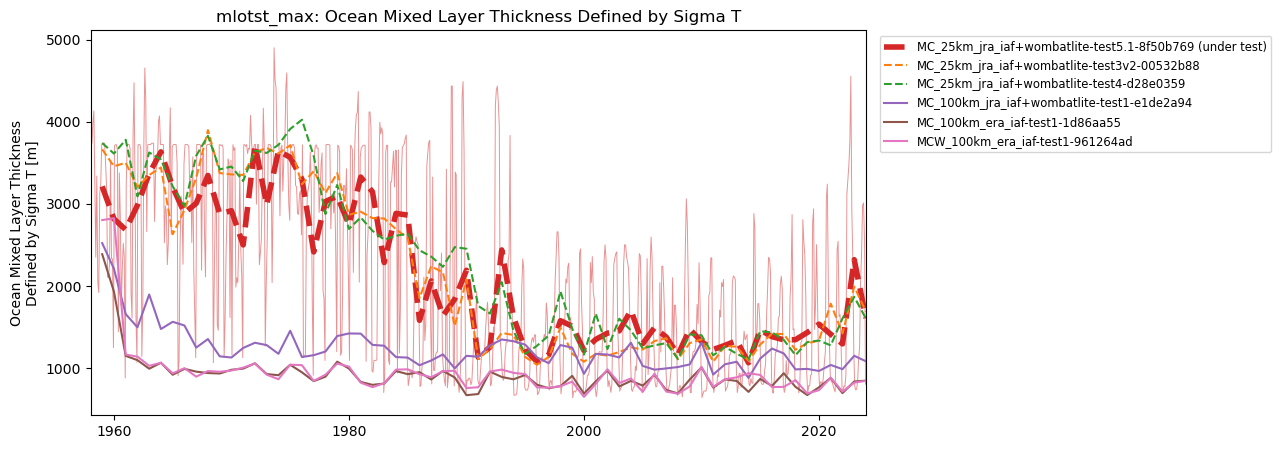

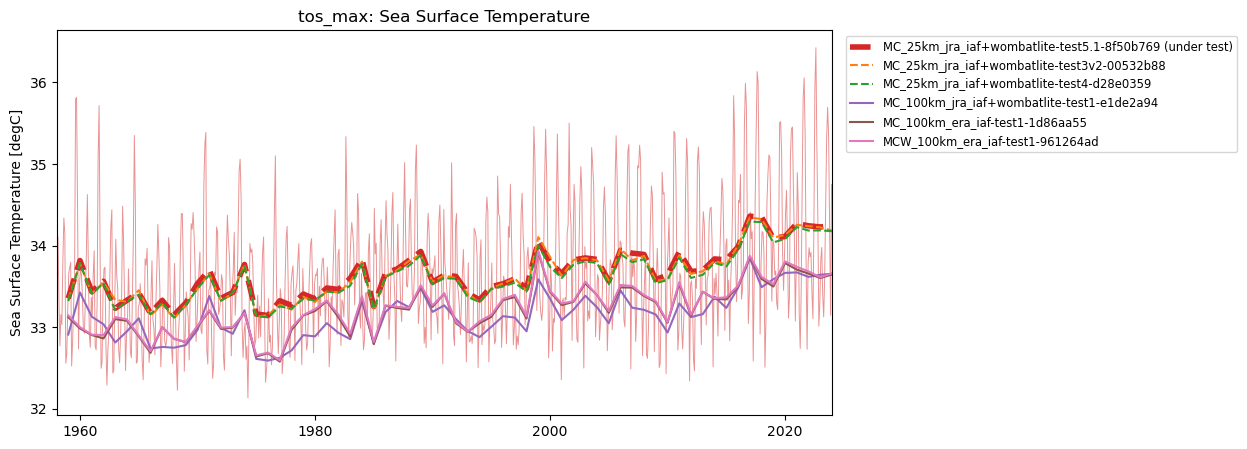

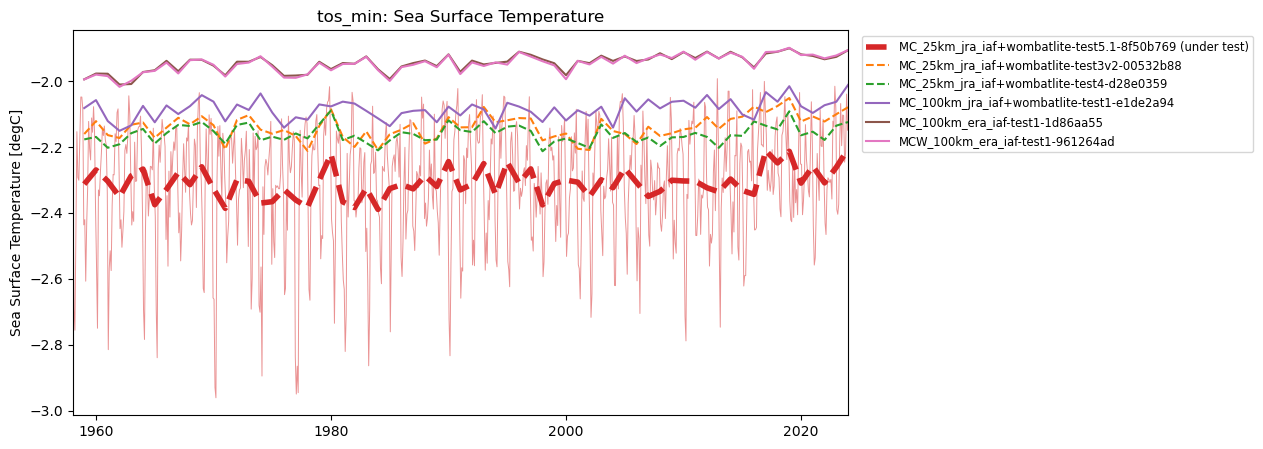

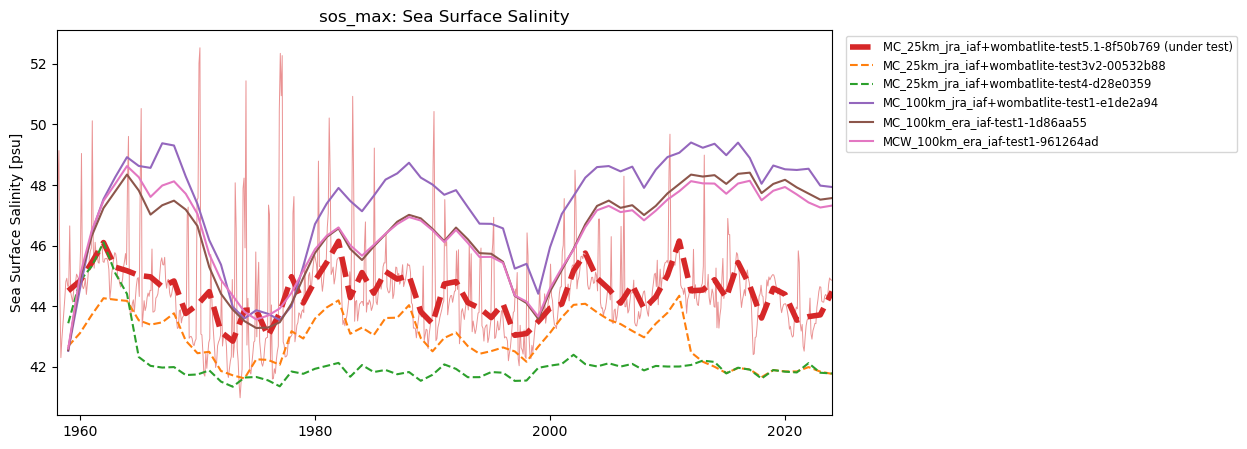

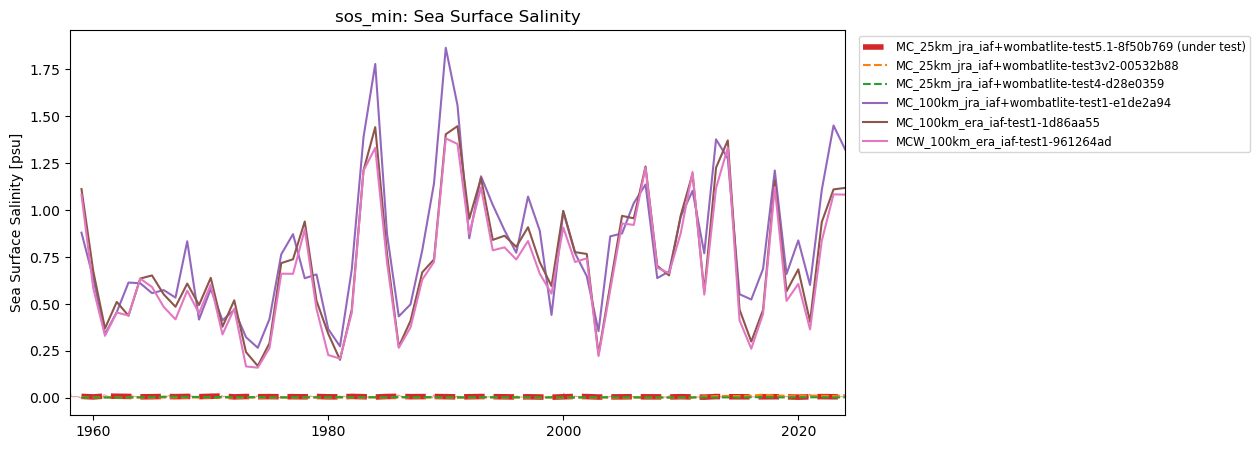

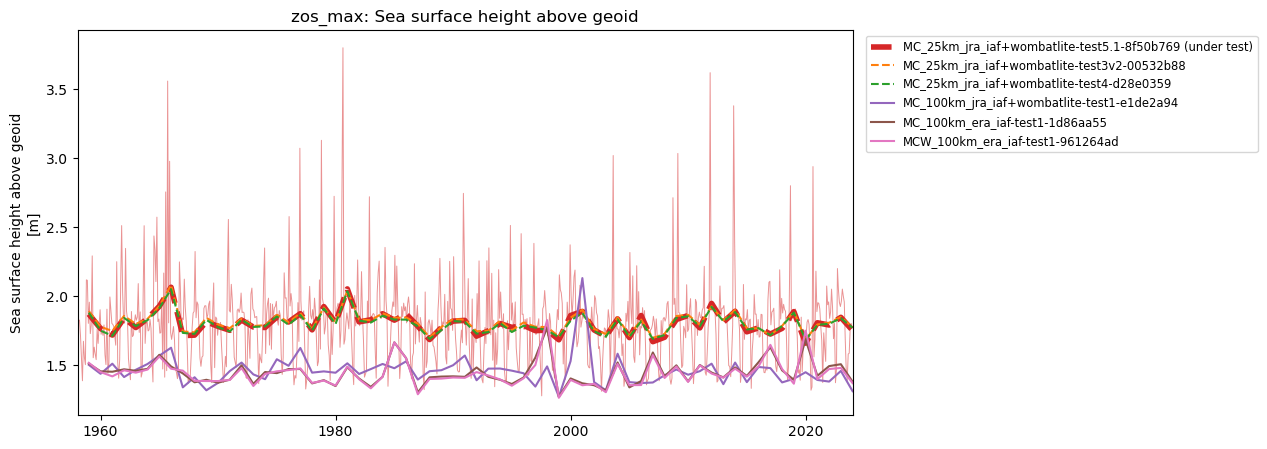

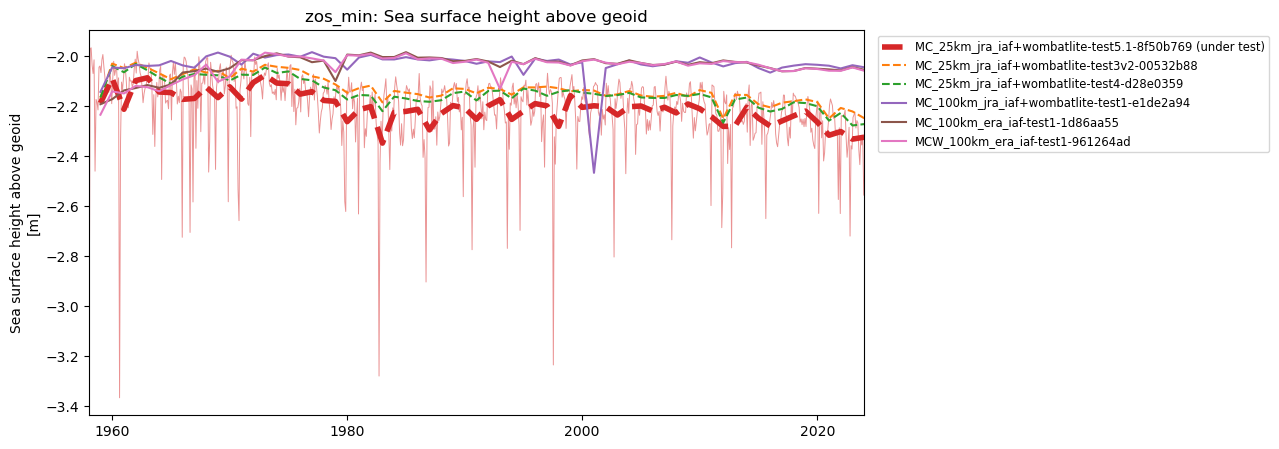

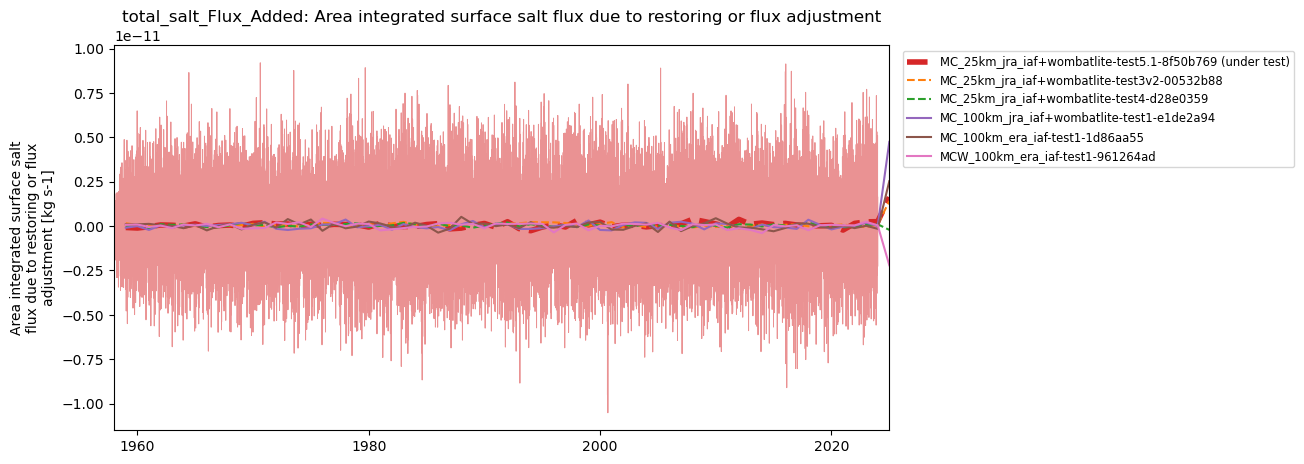

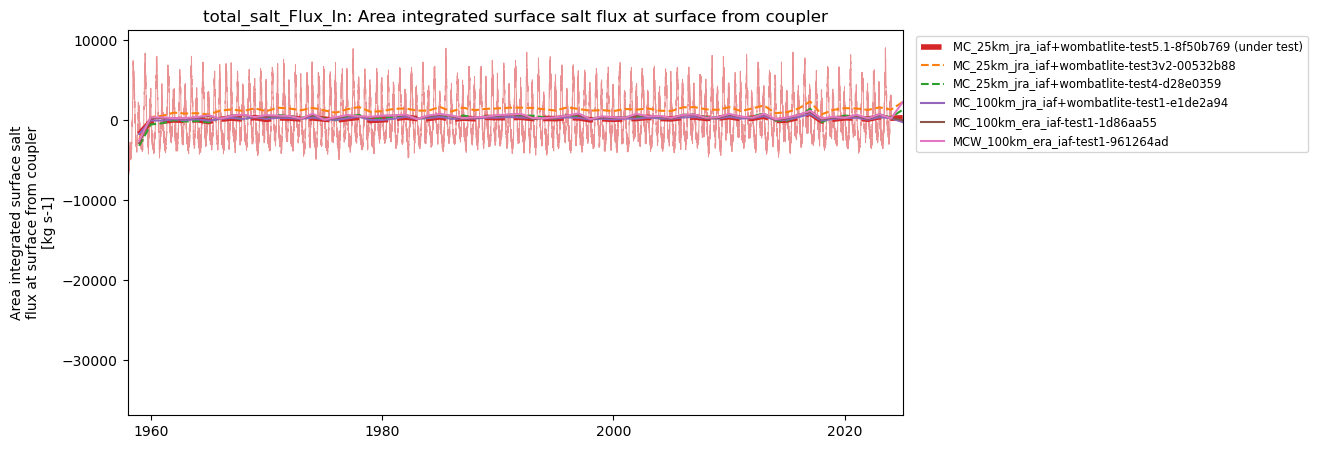

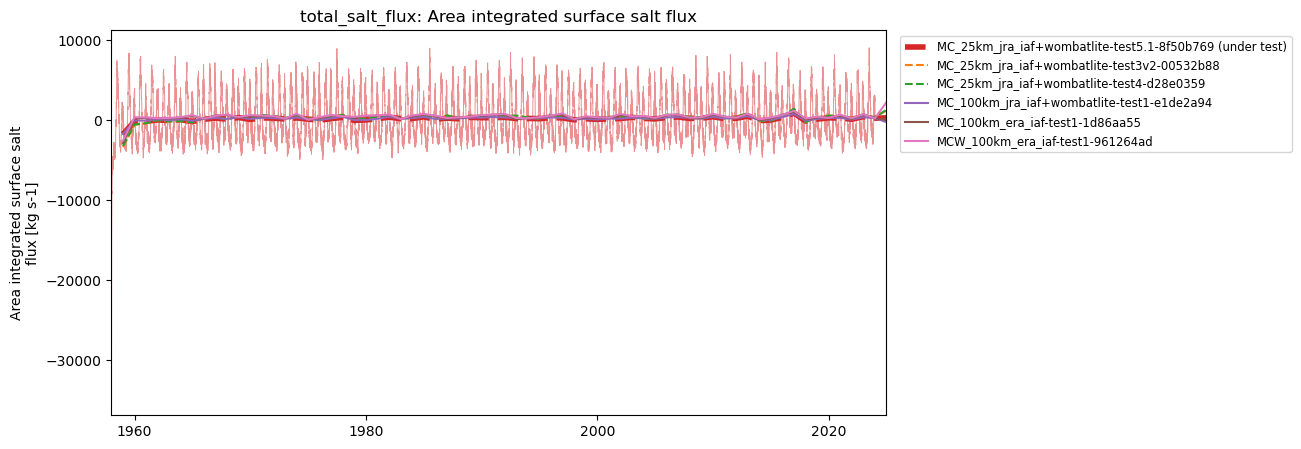

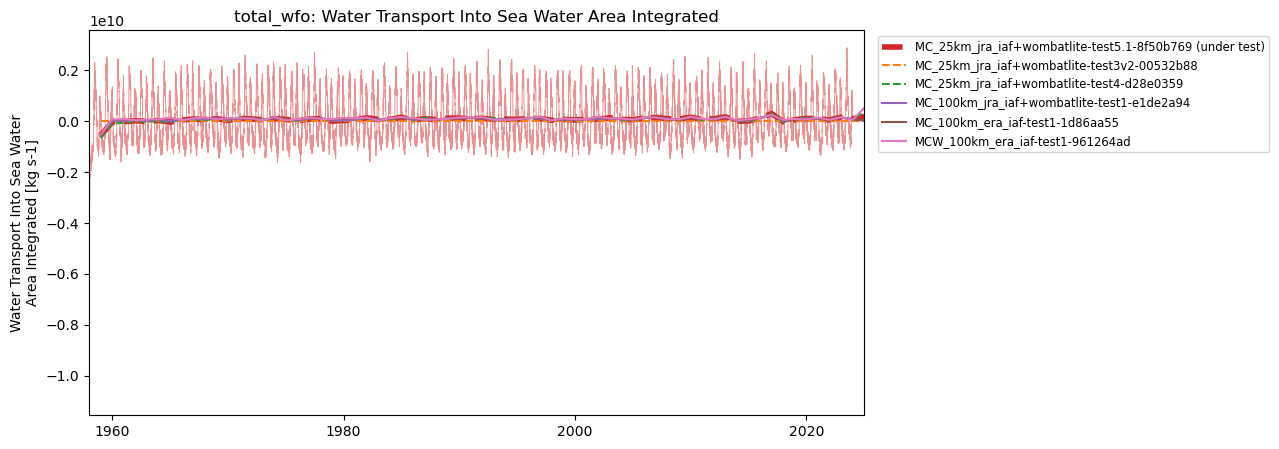

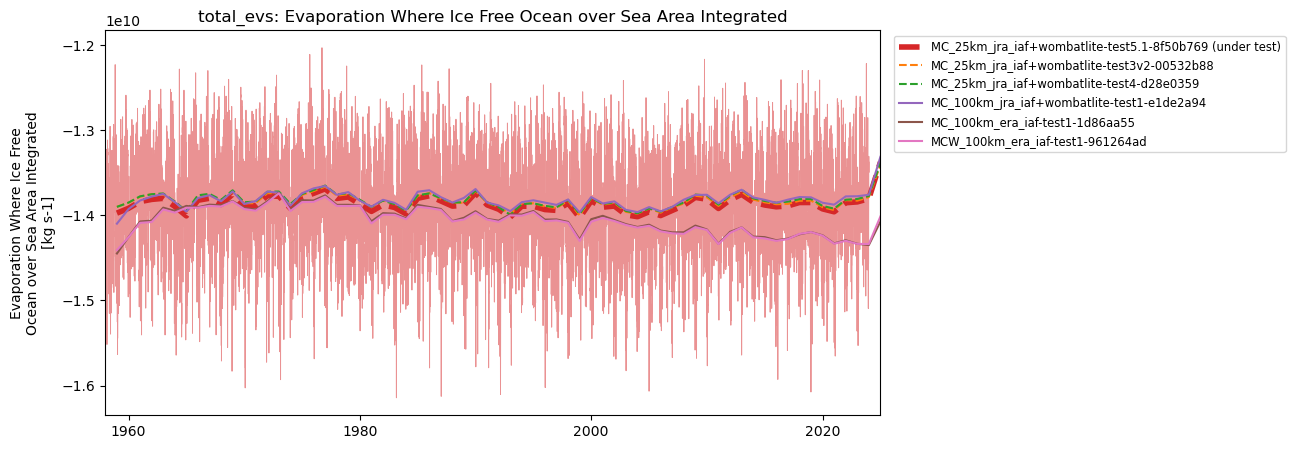

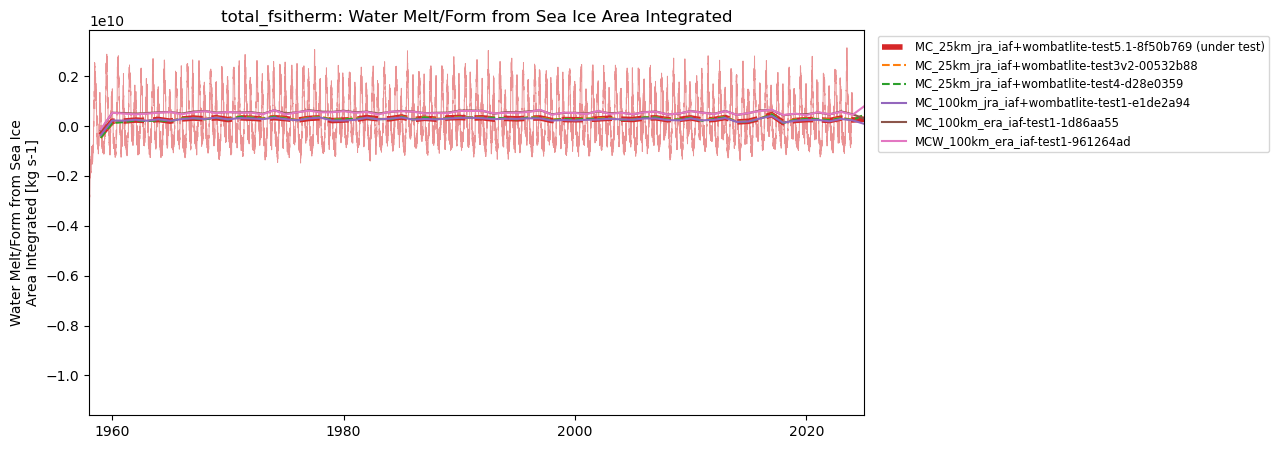

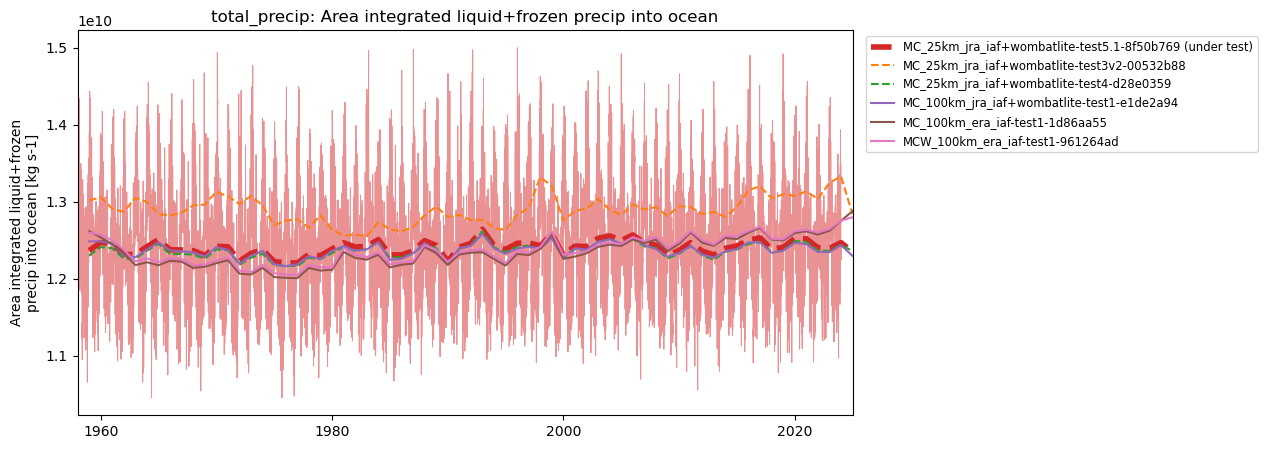

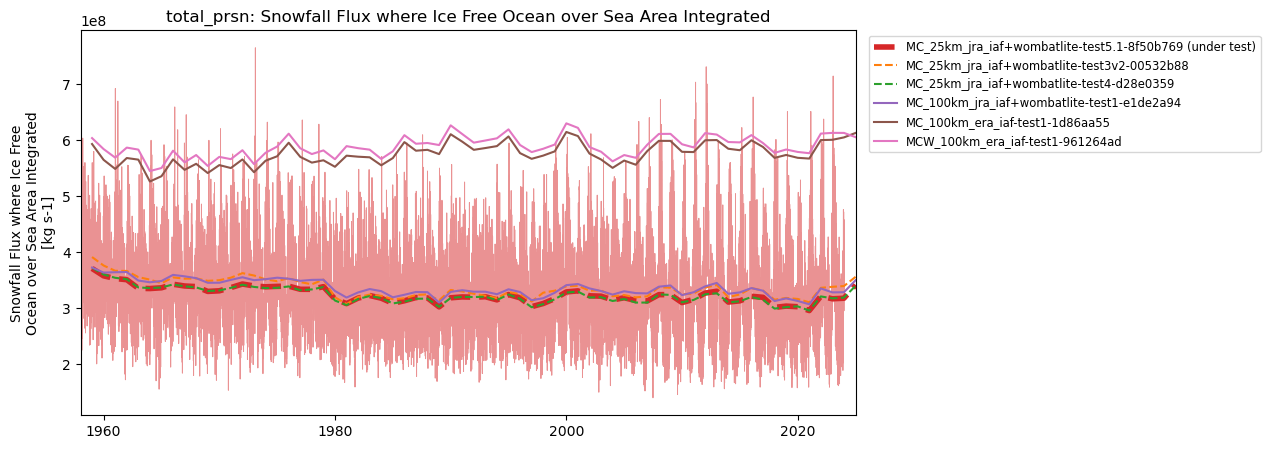

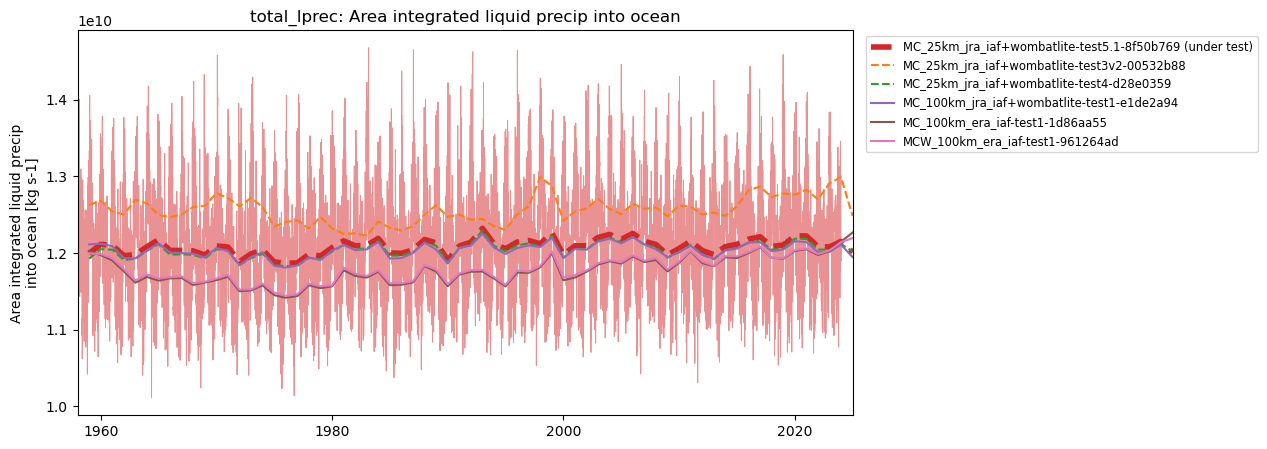

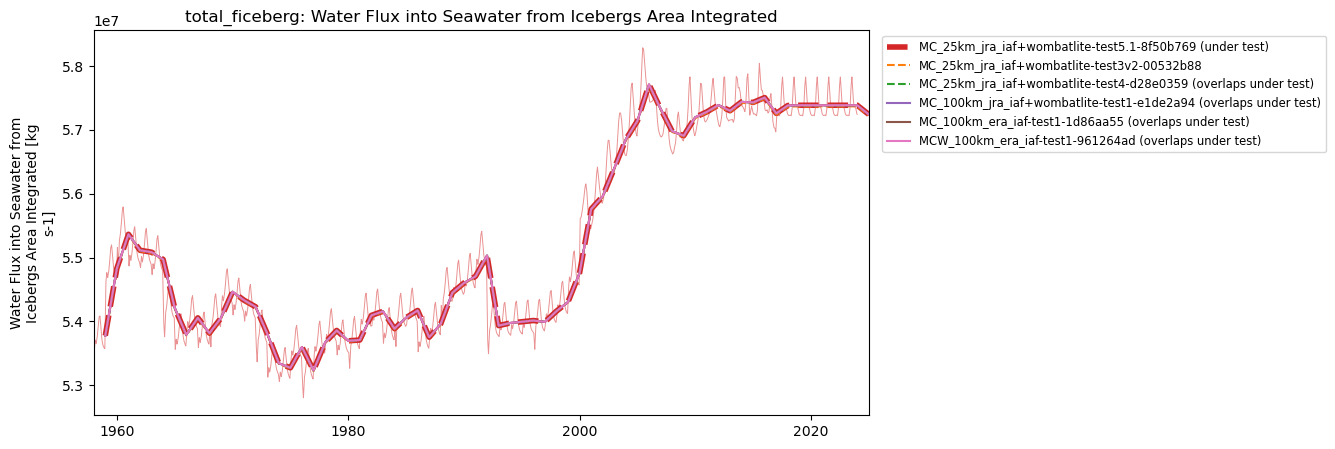

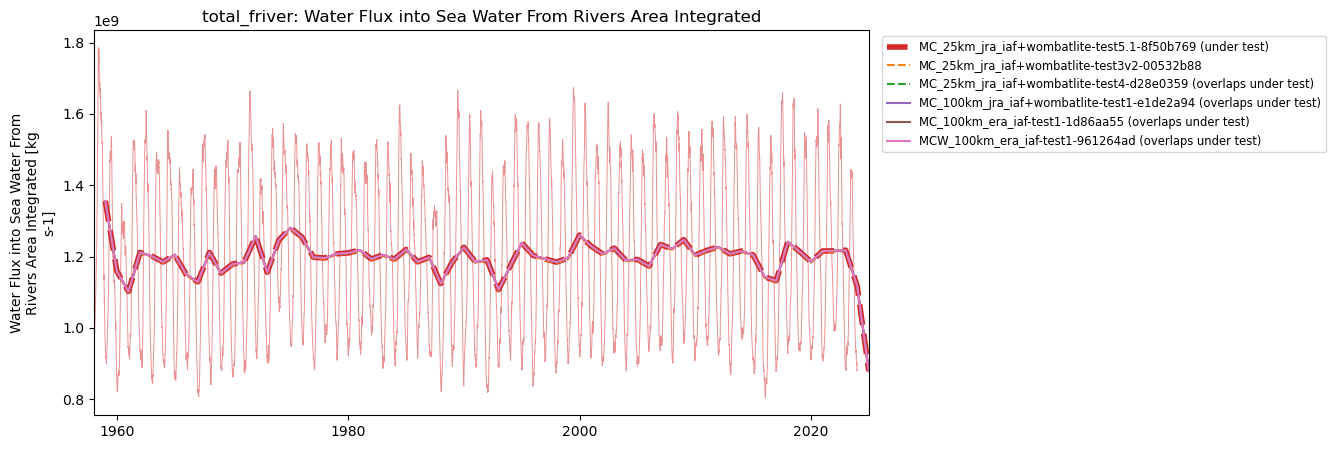

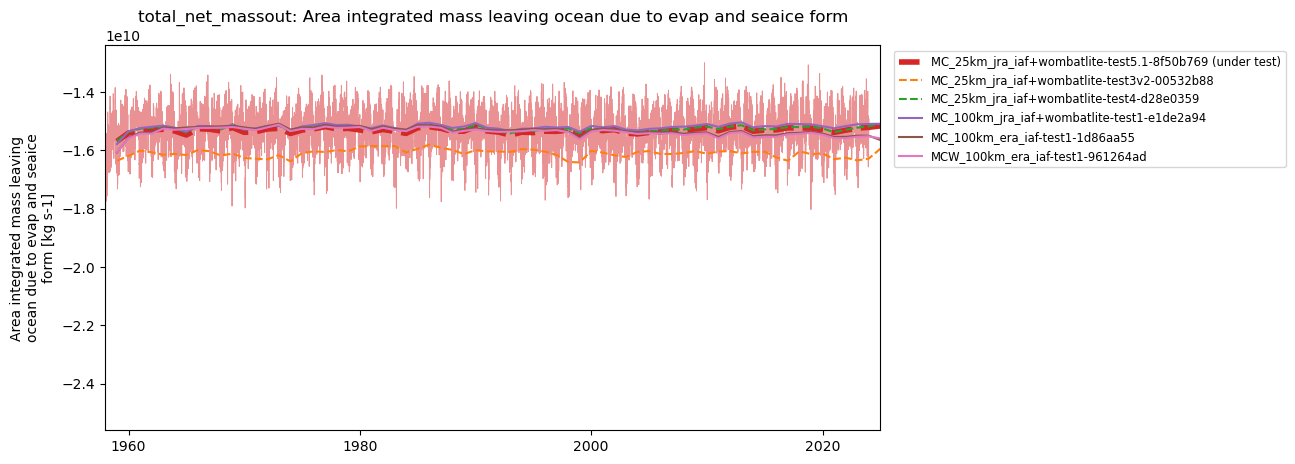

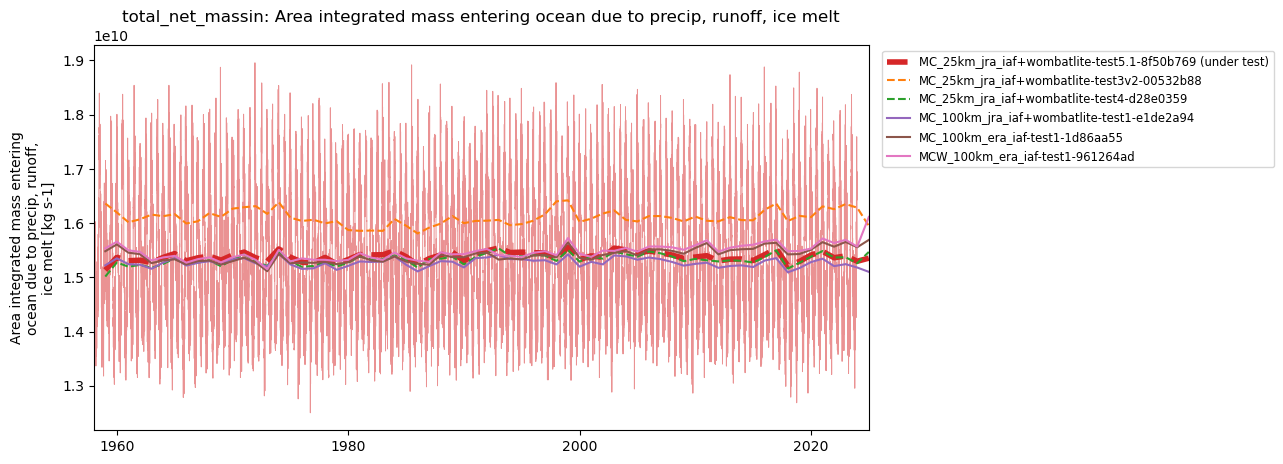

In [20]:
for k, d in data.items():
    print(k)
    fname = thisdir+k+'_'+list(d.values())[-1][k].attrs['long_name'].replace(' ', '_').replace('/','_')+'.png'
    # print(fname)
    if False: #os.path.isfile(fname):
        print(f'---- skipping existing file {fname}')
    else:
        plt.figure(figsize=(10,5))
        ax = plt.subplot(111)
        span = plot_span(d, k)
        annual_under_test = None
        for n, ds in d.items():
            dat = ds[k].sel(time=span)
            if dat.time.size == 0:  # no overlap with the experiment under test
                continue
            if dat.cell_methods.find('time: mean') >= 0:
                # calculate spatial average if needed
                if 'depth' in dat.cf.coords: # https://xgcm.readthedocs.io/en/latest/grid_metrics.html?highlight=average#Grid-aware-(weighted)-average
                    dat = grid.average(dat, ['X', 'Y', 'Z'])
                elif 'longitude' in dat.cf.coords: # https://xgcm.readthedocs.io/en/latest/grid_metrics.html?highlight=average#Grid-aware-(weighted)-average
                    dat = grid.average(dat, ['X', 'Y'])
            elif dat.cell_methods.find('time: max') >= 0:
                dat = dat.cf.max(dim=['longitude', 'latitude'])
            elif dat.cell_methods.find('time: min') >= 0:
                dat = dat.cf.min(dim=['longitude', 'latitude'])
            # dat = dat - dat.isel(time=0)
            dat.load()
            # if int((dat.time[1]-dat.time[0]).values/1e9/60/60/24) == 1:
            #     label = 'daily'
            # else:
            #     label = 'monthly mean' # possible BUG: plausible guess
            # p = dat.plot(label=' '.join([n, label]), linewidth=1)
            under_test = n == exptname
            if under_test:  # thin: every value (daily or monthly), for the experiment under test only
                dat.plot(linewidth=.7, color=experiment_colours[n], alpha=.5, zorder=1)
            # thick: annual mean, line style by resolution. The experiment under test is thickest and drawn
            # underneath, so a comparison run with (nearly) identical values, e.g. a field set by the forcing,
            # shows as a thin line inside it instead of being hidden by it
            annual = dat.cf.resample(time='1YE').mean('time')
            label = n
            if under_test:
                annual_under_test = annual
                label = f"{n} (under test)"
            elif annual_under_test is not None:
                # say so when a run can't be told apart from the experiment under test at this scale:
                # annual means within 0.1% of the range of the experiment under test
                a, b = xr.align(annual, annual_under_test, join="inner")
                spread = float(annual_under_test.max() - annual_under_test.min())
                if a.size and float(abs(a - b).max()) <= 1e-3 * spread:
                    label = f"{n} (overlaps under test)"
            annual.plot(
                color=experiment_colours[n],
                linestyle=experiment_linestyles[n],
                linewidth=4 if under_test else 1.5,
                zorder=1.5 if under_test else 2,
                label=label
            )
            # dat.cf.rolling(time=12, center=True).mean('time').plot()
            # dat.cf.rolling(time='1YE', center=True).mean('time').plot()
        # NB: title from first item (OM3), but y axis label from last item (may be OM2)
        # plt.title(k+': '+list(d.values())[0][k].attrs['long_name'])
        plt.title(f'{k}: {dat.attrs["long_name"]}')
        plt.xlabel('')
        plt.autoscale(enable=True, axis='x', tight=True)
        plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize="small")
        # # Shrink current axis's height from the bottom
        # box = ax.get_position()
        # ax.set_position([box.x0, box.y0 + box.height * 0.4,
        #                  box.width, box.height * 0.6])
        # # Put a legend below current axis
        # ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08))
        # # try:
        #     plt.savefig(fname, dpi=150)
        #     print(f'saved {fname}')
        # except FileNotFoundError:
        #     print(f'*** FileNotFoundError when saving {fname}')
        # break
    mkmd.savefig(plt.gcf(), f"Timeseries: {k}", "ACCESS-OM3 global model timeseries. Thick lines: annual means (thickest, drawn underneath: experiment under test, so identical runs stay visible); thin line: every value of the experiment under test. Line style: solid 100km, dashed 25km, dotted 8km; black: ACCESS-OM2 reference. [GitHub issue: Global average annual mean time series](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/3)")

## Water balance checks

How ocean water and salt are balanced depends on the MOM6 configuration, which differs between experiments
(see https://github.com/ACCESS-NRI/access-om3-configs/issues/920). The checks below are for the experiment under test,
and which ones apply is decided from its output:

- **Water mass drift** (always shown): monthly-mean ocean mass (`masso`), sea-ice + snow mass (from CICE `hi`, `hs`
  and `tarea`, with CICE densities 917 and 330 kg m-3; salt in the ice is neglected) and their total, as change in
  global-mean sea-level equivalent. With `ADJUST_NET_FRESH_WATER_TO_ZERO = True` ocean mass is held constant, so the
  total changes with sea ice. Recent configurations set it `False` and instead balance freshwater in the CMEPS
  mediator (`med_phases_scalefreshwater_run` in `nuopc.runseq`): every coupling step, rain and snow are scaled so that
  global precipitation + evaporation + runoff into ocean and sea ice is zero. Then the **total** should be flat, while
  ocean mass changes as water moves into and out of sea ice.
- **Net freshwater adjustment** (only if `net_fresh_water_global_adjustment` is output and non-zero): with
  `ADJUST_NET_FRESH_WATER_TO_ZERO = True`, MOM6 removes the global net freshwater flux into the ocean every step,
  including the sea-ice melt/formation flux, as a uniform `vprec`. `net_fresh_water_global_adjustment` [kg m-2 s-1]
  is the flux removed; times ocean area and minus `total_fsitherm`, it is the precipitation + evaporation + runoff
  imbalance that was removed.
- **Salt restoring balance**: the restoring salt flux is balanced either by a uniform offset
  (`salt_flux_global_restoring_adjustment`) or, with `ADJUST_NET_SRESTORE_BY_SCALING = True`, by scaling down its
  positive or negative part (`salt_flux_global_restoring_scaling`: a value in (0, 1] is the factor applied to the
  positive part, in [-1, 0) minus the factor applied to the negative part; the adjustment is then zero).
  `total_salt_Flux_Added` should be ~0 in both cases.

In [21]:
esm_name = get_exptname_from_path(esm_file)
esm_name

'MC_25km_jra_iaf+wombatlite-test5.1-8f50b769'

In [22]:
masked_areacello = static['areacello'].where(static['wet'] > 0)  # areacello is not land-masked

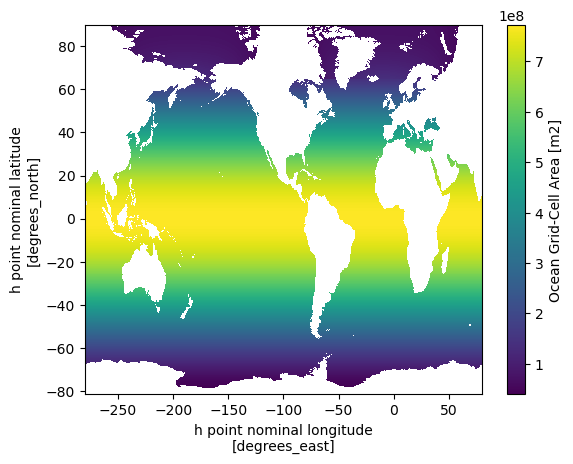

In [23]:
masked_areacello.plot()

In [24]:
total_ocean_area = masked_areacello.sum().load()

In [25]:
def scalar_series(k):
    """Field k of the experiment under test as a 1-D time series, or None if it was not loaded."""
    if esm_name not in data.get(k, {}):
        return None
    return data[k][esm_name][k].squeeze(drop=True).load()

masso = scalar_series('masso')
total_fsitherm = scalar_series('total_fsitherm')
net_fw_adjustment = scalar_series('net_fresh_water_global_adjustment')  # None if not output or zero throughout

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:316: ConcatenationWarning: Attempting to concatenate datasets without valid dimension coordinates: retaining only first dataset. Request valid dimension coordinate to silence this warning.
  warnings.warn(


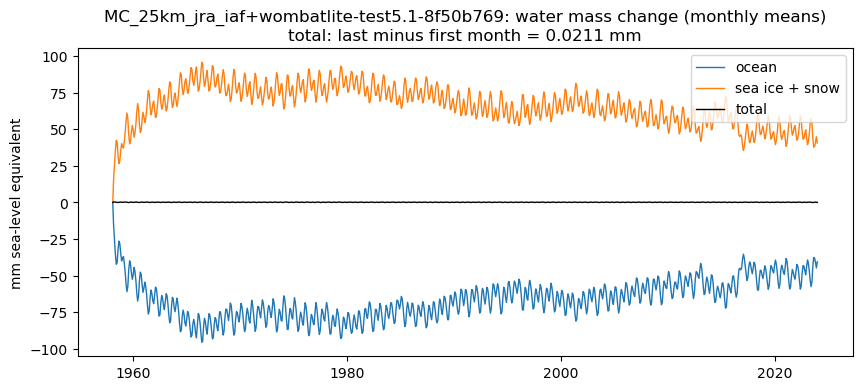

In [26]:
# Water mass drift as global-mean sea-level equivalent: ocean, sea ice + snow, and their total
rho0 = 1035.0              # [kg m-3] RHO_0 in ACCESS-OM3 MOM_input (Boussinesq: ocean mass = RHO_0 * volume)
rhoi, rhos = 917.0, 330.0  # [kg m-3] CICE sea-ice and snow densities

def sea_ice_mass():
    """Monthly-mean global sea-ice + snow mass [kg] of the experiment under test, or None if it isn't output."""
    datastore = datastores[esm_name]
    # CICE writes monthly-mean thicknesses as hi_m/hs_m (frequency 1mon) and daily ones as hi/hs (1day).
    # Use the monthly pair when output (about 30 times less data), else the daily pair. Never mix the two.
    for hi_name, hs_name in (("hi_m", "hs_m"), ("hi", "hs")):
        if all(not datastore.search(variable=v).df.empty for v in (hi_name, hs_name, "tarea")):
            break
    else:  # e.g. ACCESS-CM3
        print(f"CICE hi_m/hs_m or hi/hs, and tarea, not output by {esm_name}")
        return None
    loaded = {v: load_variable(datastore, v, xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs)
              for v in (hi_name, hs_name, "tarea")}
    hi, hs, tarea = loaded[hi_name][hi_name], loaded[hs_name][hs_name], loaded["tarea"]["tarea"]
    if "time" in tarea.dims:
        tarea = tarea.isel(time=0, drop=True)
    # hi, hs are grid-cell mean thicknesses [m]
    mass = ((rhoi * hi.fillna(0) + rhos * hs.fillna(0)) * tarea.fillna(0)).sum([d for d in hi.dims if d != "time"])
    if IAF:  # same calendar normalisation as the other IAF data
        mass = mass.convert_calendar("proleptic_gregorian", use_cftime=True)
    return mass.resample(time="1ME").mean().load()

if masso is None:
    print(f"masso not output by {esm_name}")
else:
    water = {"ocean": masso.resample(time="1ME").mean()}
    ice_mass = sea_ice_mass()
    if ice_mass is None:
        print("Showing ocean mass only")
    else:
        ocean, ice_mass = xr.align(water["ocean"], ice_mass, join="inner")
        water = {"ocean": ocean, "sea ice + snow": ice_mass, "total": ocean + ice_mass}
    to_mm = lambda m: (m - m.isel(time=0)) / (rho0 * total_ocean_area) * 1e3
    fig, ax = plt.subplots(figsize=(10, 4))
    for (name, m), colour in zip(water.items(), ["C0", "C1", "k"]):
        to_mm(m).plot(ax=ax, linewidth=1, color=colour, label=name)
    last = list(water)[-1]
    change = float(to_mm(water[last])[-1])  # drift need not be linear (e.g. spin-up), so no trend
    ax.set_title(f'{esm_name}: water mass change (monthly means)\n{last}: last minus first month = {change:.3g} mm')
    ax.set_ylabel('mm sea-level equivalent')
    ax.set_xlabel('')
    ax.legend()

In [27]:
if net_fw_adjustment is None:
    print(f"{esm_name} has no net freshwater adjustment (ADJUST_NET_FRESH_WATER_TO_ZERO = False, "
          "or net_fresh_water_global_adjustment not output): ocean mass is free to change, see the drift above.")
else:
    adjustment_total = net_fw_adjustment * total_ocean_area  # [kg s-1]
    series = {'net_fresh_water_global_adjustment * ocean area': adjustment_total}
    if total_fsitherm is not None:
        series['total_fsitherm (sea-ice melt/formation)'] = total_fsitherm
        series['difference: precipitation + evaporation + runoff imbalance'] = adjustment_total - total_fsitherm
    fig, ax = plt.subplots(figsize=(10, 4))
    for i, (label, s) in enumerate(series.items()):
        s.plot(ax=ax, linewidth=.3, color=f'C{i}', alpha=.5)
        s.resample(time='1YE').mean().plot(ax=ax, linewidth=2, color=f'C{i}', label=label + ' (annual mean)')
    ax.set_title(f'{esm_name}: net freshwater removed by ADJUST_NET_FRESH_WATER_TO_ZERO')
    ax.set_ylabel('kg s-1')
    ax.set_xlabel('')
    ax.legend()

MC_25km_jra_iaf+wombatlite-test5.1-8f50b769 has no net freshwater adjustment (ADJUST_NET_FRESH_WATER_TO_ZERO = False, or net_fresh_water_global_adjustment not output): ocean mass is free to change, see the drift above.


In [28]:
# Salt restoring balance of the experiment under test
salt_added = scalar_series('total_salt_Flux_Added')
salt_adjustment = scalar_series('salt_flux_global_restoring_adjustment')  # None if not output or zero throughout
salt_scaling = scalar_series('salt_flux_global_restoring_scaling')
if salt_added is not None:
    print(f"total_salt_Flux_Added: max |value| = {float(abs(salt_added).max()):.3g} kg s-1 (~0 if restoring is balanced)")
if salt_adjustment is not None:
    print("Restoring balanced by a uniform offset: see the salt_flux_global_restoring_adjustment panel above")
elif salt_scaling is not None:
    print("Restoring balanced by scaling: see the salt_flux_global_restoring_scaling panel above")
else:
    print("No non-zero salt-restoring balance diagnostic. With ADJUST_NET_SRESTORE_BY_SCALING = True the adjustment "
          "is zero by design; add salt_flux_global_restoring_scaling to diag_table to see the scaling.")

total_salt_Flux_Added: max |value| = 1.05e-11 kg s-1 (~0 if restoring is balanced)
No non-zero salt-restoring balance diagnostic. With ADJUST_NET_SRESTORE_BY_SCALING = True the adjustment is zero by design; add salt_flux_global_restoring_scaling to diag_table to see the scaling.
